## CAPSTONE PROJECT BRIEF BY OLOWOLADE TREASURE SIMILOLUWA

# Dataset Overview

This dataset contains customer and transaction information from a telecommunications business(MTN). It covers customer details, purchase history, subscription plans, device types, data usage, satisfaction levels, revenue, and customer churn.

The dataset includes both numerical and categorical variables such as age, state, gender, satisfaction rate, customer tenure, unit price, number of purchases, total revenue, data usage, and churn status.

The main aim of this analysis is to understand customer behaviour and identify patterns in areas such as revenue, data usage, customer satisfaction, and churn. The findings will be used to highlight key business insights and suggest practical recommendations that could support better customer retention and business performance.

Each row represents a customer-related purchase or subscription record, so some customers may appear more than once in the dataset.


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\archive (3)\mtn_customer_churn.csv")

In [3]:
df.head()

,Customer ID,Full Name,Date of Purchase,Age,State,MTN Device,Gender,Satisfaction Rate,Customer Review,Customer Tenure in months,Subscription Plan,Unit Price,Number of Times Purchased,Total Revenue,Data Usage,Customer Churn Status,Reasons for Churn
0,CUST0001,Ngozi Berry,Jan-25,27,Kwara,4G Router,Male,2,Fair,2,165GB Monthly Plan,35000,19,665000,44.48,Yes,Relocation
1,CUST0002,Zainab Baker,Mar-25,16,Abuja (FCT),Mobile SIM Card,Female,2,Fair,22,12.5GB Monthly Plan,5500,12,66000,19.79,Yes,Better Offers from Competitors
2,CUST0003,Saidu Evans,Mar-25,21,Sokoto,5G Broadband Router,Male,1,Poor,60,150GB FUP Monthly Unlimited,20000,8,160000,9.64,No,NaN
3,CUST0003,Saidu Evans,Mar-25,21,Sokoto,Mobile SIM Card,Male,1,Poor,60,1GB+1.5mins Daily Plan,500,8,4000,197.05,No,NaN
4,CUST0003,Saidu Evans,Mar-25,21,Sokoto,Broadband MiFi,Male,1,Poor,60,30GB Monthly Broadband Plan,9000,15,135000,76.34,No,NaN


In [4]:
# Checking for the columns and row of the dataset

df.shape

(974, 17)

974 rows and 17 columns are in this datasets

In [23]:
# Checking for missing values

df.isnull().sum()

Customer ID                  0
Full Name                    0
Date of Purchase             0
Age                          0
State                        0
MTN Device                   0
Gender                       0
Satisfaction Rate            0
Customer Review              0
Customer Tenure in months    0
Subscription Plan            0
Unit Price                   0
Number of Times Purchased    0
Total Revenue                0
Data Usage                   0
Customer Churn Status        0
Reasons for Churn            0
dtype: int64

It was observed that all other columns were without missing values except the "Reasons for churn" column

In [6]:
# see missing values as a percentage

missing_percentage = (df.isnull().sum()) / (len(df)) * 100
print(missing_percentage.round(2))

Customer ID                   0.00
Full Name                     0.00
Date of Purchase              0.00
Age                           0.00
State                         0.00
MTN Device                    0.00
Gender                        0.00
Satisfaction Rate             0.00
Customer Review               0.00
Customer Tenure in months     0.00
Subscription Plan             0.00
Unit Price                    0.00
Number of Times Purchased     0.00
Total Revenue                 0.00
Data Usage                    0.00
Customer Churn Status         0.00
Reasons for Churn            70.84
dtype: float64


This shows that 70.84% of the "Reason for churn" column are missing

In [7]:
# Fill the "Reason for churn" column with a specific value
df['Reasons for Churn'] = df['Reasons for Churn'].fillna('Still a customer')
print(df['Reasons for Churn'].value_counts().head())

Reasons for Churn
Still a customer                  690
High Call Tarriffs                 54
Better Offers from Competitors     52
Poor Network                       45
Costly Data Plans                  40
Name: count, dtype: int64


I filling this missing values with a specific values which is "still a customer", because the reason for this empty rows in this column is due to the fact that this customers are still using the MTN service, so they had no reason to churn.

In [8]:
# check how many duplicate rows existt

print(f'Duplicate rows: {df.duplicated().sum()}')

Duplicate rows: 0


No duplicate row was found

In [9]:
# check current data types

print(df.dtypes)

Customer ID                   object
Full Name                     object
Date of Purchase              object
Age                            int64
State                         object
MTN Device                    object
Gender                        object
Satisfaction Rate              int64
Customer Review               object
Customer Tenure in months      int64
Subscription Plan             object
Unit Price                     int64
Number of Times Purchased      int64
Total Revenue                  int64
Data Usage                   float64
Customer Churn Status         object
Reasons for Churn             object
dtype: object


In [10]:
df.describe()

,Age,Satisfaction Rate,Customer Tenure in months,Unit Price,Number of Times Purchased,Total Revenue,Data Usage
count,974.000000,974.000000,974.000000,974.000000,974.000000,9.740000e+02,974.000000
mean,48.043121,2.947639,31.422998,19196.663244,10.564682,2.046696e+05,99.304764
std,17.764307,1.384219,17.191256,25586.726985,5.709427,3.247855e+05,57.739511
min,16.000000,1.000000,1.000000,350.000000,1.000000,3.500000e+02,0.820000
25%,32.000000,2.000000,17.000000,5500.000000,5.000000,3.300000e+04,47.637500
50%,49.000000,3.000000,31.000000,14500.000000,11.000000,1.080000e+05,103.330000
75%,63.750000,4.000000,47.000000,24000.000000,15.000000,2.610000e+05,149.697500
max,80.000000,5.000000,60.000000,150000.000000,20.000000,3.000000e+06,200.000000


In [11]:
Gender_by_Total_Revenue = df.groupby('Gender')['Total Revenue'].sum().round(2)
print(Gender_by_Total_Revenue)

Gender
Female    104415650
Male       94932550
Name: Total Revenue, dtype: int64


### Gender and Total Revenue

The analysis shows that female customers generated a higher total revenue of ₦104.4 million, compared to ₦94.9 million generated by male customers. This means female customers contributed about ₦9.5 million more to the total revenue in this dataset.

This difference suggests that female customers made a larger contribution to revenue during the period covered by the dataset. However, this does not necessarily mean that individual female customers spent more, since the result is based on total revenue rather than average revenue per customer.

In [12]:
Data_usage_by_device = df.groupby('MTN Device')['Data Usage'].mean().round(2)
print(Data_usage_by_device)

MTN Device
4G Router               96.39
5G Broadband Router     95.15
Broadband MiFi         103.46
Mobile SIM Card        101.40
Name: Data Usage, dtype: float64


### Average Data Usage by Device

The analysis shows that Broadband MiFi users recorded the highest average data usage at 103.46, followed by Mobile SIM Card users at 101.40. 4G Router users had an average usage of 96.39, while 5G Broadband Router users recorded the lowest average at 95.15.

The differences are not extremely large, and this suggests that average data usage is fairly similar across the different device types. However, Broadband MiFi and Mobile SIM Card users show slightly higher usage levels and may be worth further investigation when looking at customer usage patterns.

In [13]:
Top10_Revenue_by_state = df.groupby('State')['Total Revenue'].sum().sort_values(ascending=False).round(2).head(10)
print(Top10_Revenue_by_state)

State
Plateau        9463600
Ekiti          9240250
Yobe           8881700
Oyo            8600350
Edo            7937650
Niger          7740000
Zamfara        7248050
Abuja (FCT)    7180800
Borno          7043400
Osun           6965600
Name: Total Revenue, dtype: int64


### Total revenue by State 

This analysis shows that Plateau State generated the highest total revenue of ₦9,463,600, followed by Ekiti State with ₦9,240,250 and Yobe State with ₦8,881,700. Oyo and Edo also recorded substantial revenue of ₦8,600,350 and ₦7,937,650, respectively. In contrast, Osun State recorded the lowest total revenue among the ten states, at ₦6,965,600, preceded by Borno at ₦7,043,400. The difference between the highest- and lowest-performing states is ₦2,498,000. These results indicate variations in revenue generation across states, with Plateau leading the selected group. Further analysis of customer distribution, sales volume, and purchasing patterns by state would help identify the factors driving these differences and guide targeted revenue-growth strategies.

In [14]:
# Correlation matrix  

df.corr(numeric_only=True).round(2)

,Age,Satisfaction Rate,Customer Tenure in months,Unit Price,Number of Times Purchased,Total Revenue,Data Usage
Age,1.00,0.01,-0.04,-0.03,-0.00,-0.05,-0.03
Satisfaction Rate,0.01,1.00,-0.05,0.03,-0.06,-0.02,0.01
Customer Tenure in months,-0.04,-0.05,1.00,-0.03,0.06,0.01,-0.00
Unit Price,-0.03,0.03,-0.03,1.00,0.01,0.84,0.00
Number of Times Purchased,-0.00,-0.06,0.06,0.01,1.00,0.34,0.04
Total Revenue,-0.05,-0.02,0.01,0.84,0.34,1.00,0.03
Data Usage,-0.03,0.01,-0.00,0.00,0.04,0.03,1.00


### Correlation Analysis and Interpretation

The correlation matrix was used to examine the relationships between numerical variables in the dataset.

The strongest positive correlation was between Unit Price and Total Revenue, with a coefficient of **0.84**. This indicates a strong positive linear relationship, suggesting that higher unit prices tend to be associated with higher total revenue.

Number of Times Purchased and Total Revenue showed a moderate positive correlation of **0.34**, suggesting that records with more purchases tend to be associated with higher total revenue.

The strongest negative correlation was between Satisfaction Rate and Number of Times Purchased, with a coefficient of **-0.06**. However, this is a very weak negative relationship, indicating little to no meaningful linear association between the two variables.

Most of the other variables also had correlation values close to zero. For example, Age and Satisfaction Rate had a correlation of **0.01**, while Customer Tenure and Total Revenue had a correlation of **0.01**, suggesting little to no linear relationship between these pairs.

Overall, Unit Price had the strongest linear relationship with Total Revenue among the variables examined. However, correlation does not establish causation, and these results should be interpreted alongside other business factors.

In [22]:
# Outlier detection

Q1 = df['Total Revenue'].quantile(0.25)
Q3 = df['Total Revenue'].quantile(0.75)
IQR = Q3 -Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Total Revenue'] < lower_bound) | (df['Total Revenue'] > upper_bound)]

print(f'lower bound: {lower_bound:.2f}')
print(f'upper bound: {upper_bound:.2f}')

print(f'Number of outliner: {len(outliers)}')
print(outliers[['Gender', 'Total Revenue']].head(10))

lower bound: -309000.00
upper bound: 603000.00
Number of outliner: 46
     Gender  Total Revenue
0      Male         665000
36   Female         750000
52   Female        1350000
58   Female         900000
63     Male         665000
159  Female        3000000
166    Male        2250000
181  Female        1050000
184  Female        1800000
186    Male        1125000


### Outlier Analysis

The Interquartile Range (IQR) method was used to identify potential outliers in the Total Revenue column. The lower bound was calculated as -309,000, while the upper bound was 603,000. Based on these thresholds, 46 records were identified as potential outliers.

The results show that some records had unusually high revenue values, including 750,000, 1,350,000, and 3,000,000, which exceeded the upper bound. These values may represent high-value transactions rather than data entry errors. The negative lower bound is a mathematical result of the IQR calculation and does not necessarily indicate negative revenue in the dataset.

The identified outliers were retained because removing them without further investigation could lead to the loss of valid business information. These records should be reviewed to determine whether they represent genuine transactions or data quality issues.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

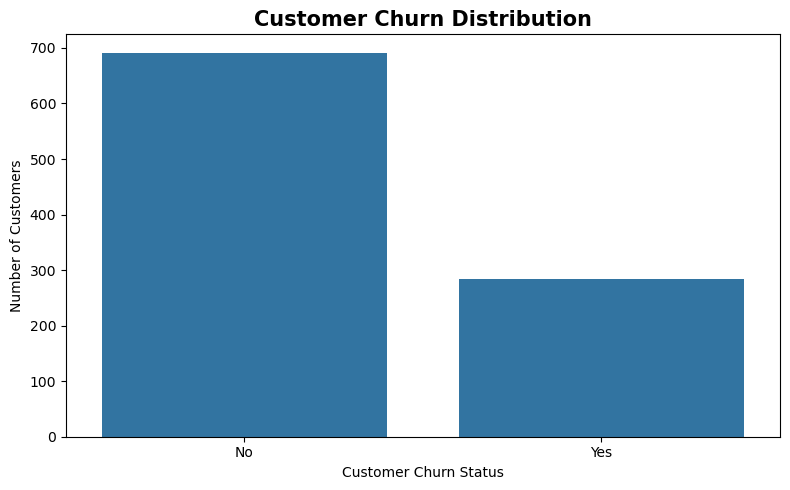

In [17]:
# Count customers by churn status
churn_counts = df['Customer Churn Status'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=churn_counts.index, y=churn_counts.values)

plt.title('Customer Churn Distribution', fontsize=15, fontweight='bold')

plt.xlabel('Customer Churn Status')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### Customer Churn Distribution

The chart shows the distribution of customers based on their churn status. Comparing customers who churned with those who remained helps establish the overall scale of customer retention and churn within the dataset.

A noticeable difference between the two groups would indicate that customer churn is an important business issue that requires further investigation. The customer who remained are greater than those who churned.

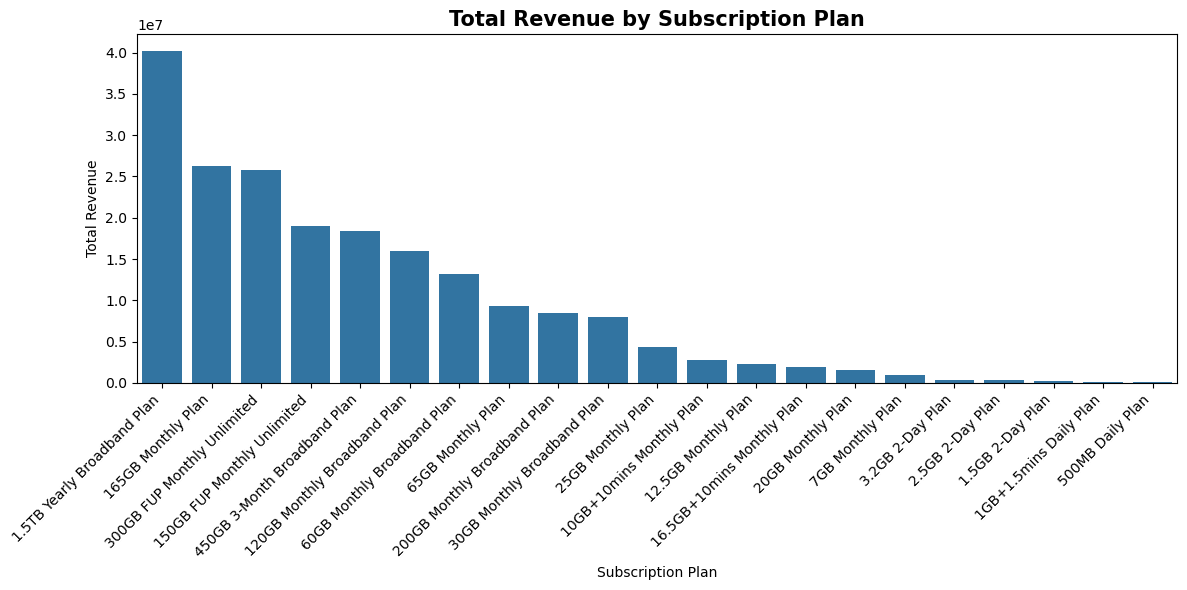

In [18]:
# Calculate total revenue by subscription plan

revenue_by_plan = (
    df.groupby('Subscription Plan')['Total Revenue']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=revenue_by_plan.index,
    y=revenue_by_plan.values
)

plt.title('Total Revenue by Subscription Plan', fontsize=15, fontweight='bold')

plt.xlabel('Subscription Plan')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Revenue by Subscription Plan

This chart compares the total revenue generated by each subscription plan. It helps identify which plans contribute most to overall revenue.

The results can help the business understand which plans have stronger financial contributions and where customer spending is concentrated.
It was observed that 1.5TB Broadband plan generates the highest revenue.

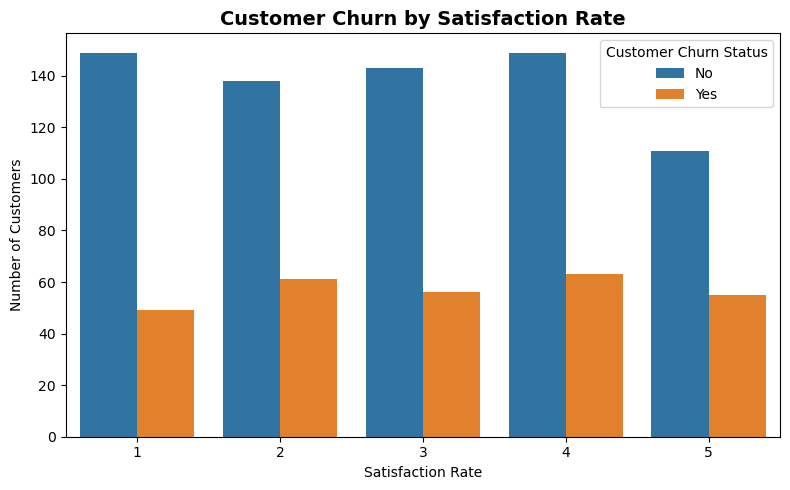

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Satisfaction Rate',
    hue='Customer Churn Status'
)

plt.title('Customer Churn by Satisfaction Rate', fontsize=14, fontweight='bold')
plt.xlabel('Satisfaction Rate')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### Customer Satisfaction and Churn

This chart compares customer churn across different satisfaction levels.

The purpose is to determine whether customers with lower satisfaction appear more frequently among customers who churned. If a clear pattern exists, customer satisfaction may be an important area for retention efforts.
This chart shows that the customer's churn status contribute to the satisfaction rate, customer's who churned contributed to the low rating. 

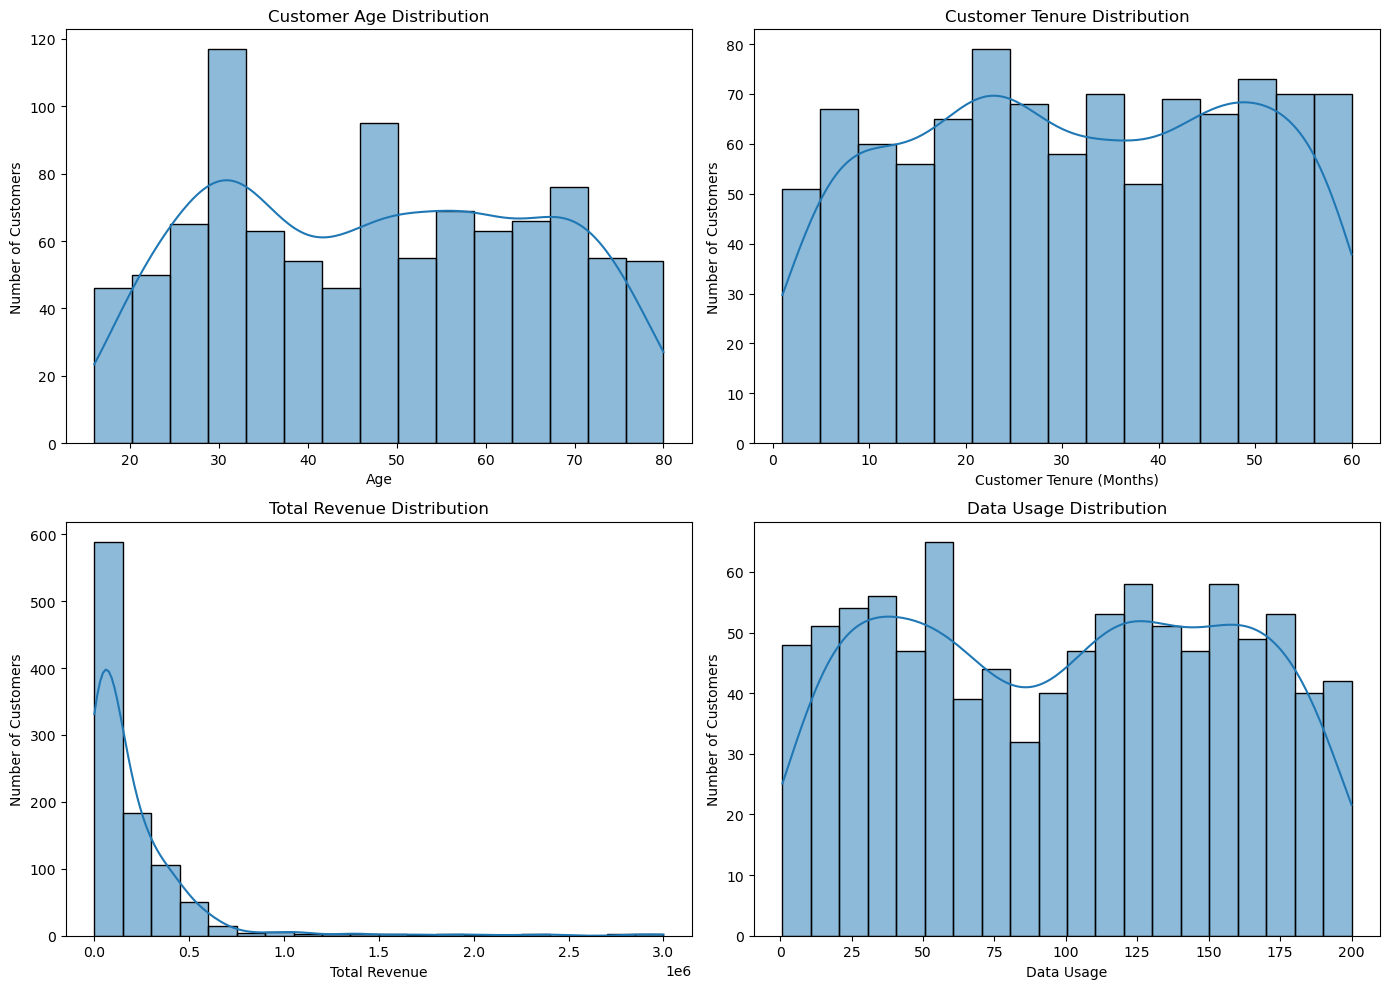

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Age distribution
sns.histplot(
    data=df,
    x='Age',
    bins=15,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Customer Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Number of Customers')


# Plot 2: Customer Tenure
sns.histplot(
    data=df,
    x='Customer Tenure in months',
    bins=15,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Customer Tenure Distribution')
axes[0, 1].set_xlabel('Customer Tenure (Months)')
axes[0, 1].set_ylabel('Number of Customers')


# Plot 3: Total Revenue
sns.histplot(
    data=df,
    x='Total Revenue',
    bins=20,
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Total Revenue Distribution')
axes[1, 0].set_xlabel('Total Revenue')
axes[1, 0].set_ylabel('Number of Customers')


# Plot 4: Data Usage
sns.histplot(
    data=df,
    x='Data Usage',
    bins=20,
    kde=True,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Data Usage Distribution')
axes[1, 1].set_xlabel('Data Usage')
axes[1, 1].set_ylabel('Number of Customers')


plt.tight_layout()
plt.show()

### Customer Behaviour Overview

This subplot grid is an overview of four important numerical characteristics of the customer base: age, customer tenure, total revenue and data usage.

These distributions help identify the general characteristics of the customers and highlight possible skewness or unusual observations that may require further investigation.

# Business Story: Understanding Customer Churn

## 1. Context

Customer retention is important to a telecommunications business because losing existing customers can reduce recurring revenue and increase the need to acquire new customers.

This analysis examines customer behaviour, satisfaction, subscription plans, revenue, data usage and customer tenure to understand patterns associated with customer churn.

## 2. Finding

The analysis shows differences in customer behaviour across churn status, particularly when comparing satisfaction levels, revenue, subscription plans and customer usage.

The churn distribution provides an overview of the scale of customer loss in the dataset, while the satisfaction analysis helps identify whether lower satisfaction is associated with a higher occurrence of churn.

## 3. Deeper Finding

Further analysis suggests that customer churn should not be examined using a single factor.

Customer satisfaction, customer tenure, subscription plan, data usage and revenue provide different perspectives on customer behaviour. For example, customers with lower satisfaction may require greater attention because dissatisfaction can be associated with customer churn.

The relationship between these variables should therefore be considered together when developing customer retention strategies.

## 4. Recommendation

The MTN business should develop a targeted customer retention strategy based on customer behaviour.

Customers showing low satisfaction and other characteristics associated with churn can be prioritised for follow-up. The company could also review subscription plans, connectivity and customer usage patterns to identify opportunities for better plan recommendations.

Regular monitoring of churn, satisfaction, revenue and usage would allow the business to identify changes in customer behaviour earlier and respond before customers leave.

# Cause, Effect and Business Impact

### Cause

The SQL analysis shows that customers who churned had an average satisfaction score of 3.05, compared with 2.91 for customers who remained. This suggests that lower satisfaction scores alone may not explain customer churn. Other factors, such as subscription plans, customer tenure, usage behaviour, and reasons for leaving, may be worth investigating.

### Effect

The results reveal a slight difference in average satisfaction between churned and retained customers, with churned customers recording the higher average. This highlights the need to examine other customer characteristics and behaviours to better understand the factors associated with churn.

### Business Impact

Understanding the factors associated with customer churn can help the business make better-informed decisions about customer retention. Further investigation into subscription plans, customer usage patterns, tenure, and recorded reasons for leaving may help identify opportunities to improve customer experience and retain customers.

# SQL Analysis

SQL was used to further analyse customer churn, revenue contribution by subscription plan, and customer satisfaction using SQL Server Management Studio (SSMS).

## SQL Query 1: Customer Churn Distribution

This query calculates the number of customers who churned and those who remained.

 SELECT 
    [Customer_Churn_Status],
    
    COUNT(*) AS Customer_Count
    
FROM mtn_customer_churn

GROUP BY [Customer_Churn_Status]

ORDER BY Customer_Count DESC;

### Interpretation

The query shows the number of customers who have churned compared with those who have remained. This provides a simple overview of the customer retention situation and supports the churn analysis carried out earlier using Python.

## SQL Query 2: Revenue by Subscription Plan

This query calculates the total revenue associated with each subscription plan.

SELECT
    [Subscription_Plan],
    
    SUM([Total_Revenue]) AS Total_Revenue
    
FROM mtn_customer_churn

GROUP BY [Subscription_Plan]

ORDER BY Total_Revenue DESC;


### Interpretation

The results show the total revenue associated with each subscription plan. This helps identify the plans contributing the most to the overall revenue in the dataset.

## SQL Query 3: Average Satisfaction by Churn Status

This query compares the average satisfaction rate between customers who churned and customers who did not churn.

SELECT
    [Customer_Churn_Status],

    AVG(CAST([Satisfaction_Rate] AS FLOAT)) AS Average_Satisfaction

FROM mtn_customer_churn

GROUP BY [Customer_Churn_Status]

ORDER BY Average_Satisfaction DESC;

### Interpretation

The SQL query shows that customers who churned had an average satisfaction score of **3.05**, while customers who did not churn had an average score of **2.91**. This indicates a small difference, with churned customers recording a slightly higher average satisfaction score than retained customers.

The result does not support the assumption that churned customers were less satisfied. It suggests that satisfaction scores alone may not explain customer churn, and other factors, such as subscription plans, customer tenure, or reasons for leaving, may also be relevant. Further analysis would be needed to understand the factors associated with churn.

#### GitHub link- https://github.com/Treasuuray